- Written by (26CD91R05) Ashutosh Kumar Barnwal

In [1]:
!pip install -q datasets

In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from datasets import load_dataset
from scipy.special import softmax

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import numpy as np


## Task 1


In [3]:
dataset = load_dataset("stanfordnlp/imdb")

print(dataset)

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [4]:
train = dataset["train"]
test = dataset["test"]


train_texts = train["text"]
train_labels = train["label"]

test_texts = test["text"]
test_labels = test["label"]

In [5]:
print(set(train_labels))

from collections import Counter

print(Counter(train_labels))

{0, 1}
Counter({0: 12500, 1: 12500})


In [ ]:
# TF-IDF features
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),      # word unigrams + bigrams
    max_features=20000
)

X_train = vectorizer.fit_transform(train_texts)
X_test = vectorizer.transform(test_texts)

y_train = train_labels
y_test = test_labels

print("Training feature shape:", X_train.shape)
print("Evaluation feature shape:", X_test.shape)


Training feature shape: (25000, 20000)
Evaluation feature shape: (25000, 20000)


In [ ]:
# Random Forest model

clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=30,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

clf.fit(X_train, y_train)


RandomForestClassifier(max_depth=30, min_samples_leaf=5, n_estimators=300,
                       n_jobs=-1, random_state=42)

In [ ]:
# Evaluation

y_pred = clf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"IMDB Accuracy: {accuracy:.4f}")

IMDB Accuracy: 0.8471


## Task 2

In [6]:
!pip install -q transformers datasets accelerate evaluate

### Initial setup

In [7]:
import os
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    set_seed,
)
from sklearn.metrics import accuracy_score
from peft import LoraConfig, TaskType, get_peft_model
from transformers import AutoModelForSequenceClassification
import gc
SEED = 42
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 512

BATCH_SIZE = 16
EPOCHS = 3
FULL_FT_LR = 2e-5
LORA_LR = 3e-4
WEIGHT_DECAY = 0.01

set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


### create a validation split from IMDB data


In [ ]:

# Reserve 10% of the original training data for validation.
splits = dataset["train"].train_test_split(
    test_size=0.1,
    seed=SEED,
    stratify_by_column="label",
)

train_data = splits["train"]
val_data = splits["test"]
test_data = dataset["test"]

print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))

print("\nExample review:")
print(train_data[0]["text"][:300])
print("Label:", train_data[0]["label"])

Train: 22500
Validation: 2500
Test: 25000

Example review:
Every generation fully believes it is living in the end times. This has been true for thousands of years now. And movies like this feed on this. How did they get the great Orson Welles to narrate this train wreck? This is a documentary about the biblical prophecies of Armageddon. It tries to link th
Label: 0


### Load tokenizer

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def preprocess_function(examples):
    return tokenizer(examples["text"], truncation=True, max_length=MAX_LENGTH)

train_data = train_data.map(preprocess_function, batched=True)
val_data = val_data.map(preprocess_function, batched=True)
test_data = test_data.map(preprocess_function, batched=True)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/22500 [00:00<?, ? examples/s]

Map:   0%|          | 0/2500 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

In [ ]:
print(train_data)

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 22500
})


# full fine-tuning

### eval matrix

In [ ]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predict = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, predict)}

### Load model

In [ ]:
full_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)


total_params = sum(p.numel() for p in full_model.parameters())
trainable_params = sum(p.numel() for p in full_model.parameters() if p.requires_grad)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total parameters: 109,483,778
Trainable parameters: 109,483,778


### train model

In [ ]:
full_training_args = TrainingArguments(
    output_dir="./imdb_full_finetuning",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    weight_decay=WEIGHT_DECAY,
    learning_rate=FULL_FT_LR,
    eval_strategy="epoch",
    save_strategy="no",
    logging_strategy="steps",
    logging_steps=100,
    report_to="none",
    seed=SEED,
    data_seed=SEED,
    fp16=torch.cuda.is_available(),)

trainer = Trainer(
    model=full_model,
    args=full_training_args,
    train_dataset=train_data,
    eval_dataset=val_data,
    compute_metrics=compute_metrics,
    data_collator=data_collator,
    processing_class = tokenizer)
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.206063,0.233610,0.920800
2,0.129630,0.267391,0.931200
3,0.076522,0.303565,0.931600


TrainOutput(global_step=4221, training_loss=0.15227660841073112, metrics={'train_runtime': 1798.624, 'train_samples_per_second': 37.529, 'train_steps_per_second': 2.347, 'total_flos': 1.759953754857768e+16, 'train_loss': 0.15227660841073112, 'epoch': 3.0})

### Evaluate on the test set

In [ ]:
full_test_metrics = trainer.evaluate(eval_dataset=test_data, metric_key_prefix="test",)
print(f"Test accuracy: {full_test_metrics['test_accuracy']:.4f}")


Training Loss,Validation Loss,Epoch,Accuracy
0.076522,0.273895,3,0.939080


Test accuracy: 0.9391


In [ ]:
full_test_metrics

{'test_loss': 0.2738950848579407, 'test_accuracy': 0.93908}

## LoRA Experiment

#### Initialisation

In [8]:
LORA_RANKS = [4, 8, 16, 32]

LORA_ALPHA_MULTIPLIER = 2
LORA_DROPOUT = 0.1

print("LoRA ranks:", LORA_RANKS)

LoRA ranks: [4, 8, 16, 32]


### Train and evaluate all four ranks

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

# import os

# SAVE_DIR = "/content/drive/MyDrive/IMDB_LoRA_Models"
# os.makedirs(SAVE_DIR, exist_ok=True)

# print("Models will be saved to:", SAVE_DIR)

In [ ]:
def lora_experiment(rank):
    print(f"Training LoRA: rank={rank}, alpha={2 * rank}")
    print("-" * 40)

    set_seed(SEED)

    base_model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=2
    )

    # LoRA configuration
    lora_config = LoraConfig(
        task_type=TaskType.SEQ_CLS,
        r=rank,
        lora_alpha=2 * rank,
        lora_dropout=LORA_DROPOUT,
        target_modules=["query", "value"],
        modules_to_save=["classifier"],
        bias="none",
    )

    model = get_peft_model(base_model, lora_config)

    trainable_params = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )
    total_params = sum(p.numel() for p in model.parameters())

    print(f"Trainable parameters: {trainable_params:,}")
    print(f"Total parameters: {total_params:,}")
    print(f"Trainable percentage: {100 * trainable_params / total_params:.4f}%")

    # Save checkpoints locally
    output_dir = f"./checkpoints_rank_{rank}"
    best_model_dir = f"./best_lora_rank_{rank}"

    training_args = TrainingArguments(
        output_dir=output_dir,
        learning_rate=LORA_LR,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=BATCH_SIZE,
        num_train_epochs=EPOCHS,
        weight_decay=WEIGHT_DECAY,

        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,

        load_best_model_at_end=True,
        metric_for_best_model="accuracy",
        greater_is_better=True,

        logging_strategy="steps",
        logging_steps=100,
        report_to="none",

        seed=SEED,
        data_seed=SEED,
        fp16=torch.cuda.is_available(),
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_data,
        eval_dataset=val_data,
        data_collator=data_collator,
        processing_class=tokenizer,
        compute_metrics=compute_metrics,
    )

    # Train and select the best checkpoint
    trainer.train()

    print("Best checkpoint:", trainer.state.best_model_checkpoint)
    print("Best validation accuracy:", trainer.state.best_metric)

    # Save best model locally
    trainer.save_model(best_model_dir)
    tokenizer.save_pretrained(best_model_dir)

    print(f"Best model saved to: {best_model_dir}")

    # Evaluate on test set
    test_metrics = trainer.evaluate(
        eval_dataset=test_data,
        metric_key_prefix="test"
    )

    accuracy = test_metrics["test_accuracy"]
    print(f"Test accuracy: {accuracy:.4f}")

    result = {
        "model": f"LoRA r={rank}",
        "rank": rank,
        "alpha": 2 * rank,
        "trainable_params": trainable_params,
        "total_params": total_params,
        "trainable_percent": 100 * trainable_params / total_params,
        "best_validation_accuracy": trainer.state.best_metric,
        "test_accuracy": accuracy,
        "saved_model_path": best_model_dir,
    }

    # Free GPU memory
    del trainer, model, base_model
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

In [9]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [ ]:
lora_results = []

for rank in LORA_RANKS:
    result = lora_experiment(rank)
    lora_results.append(result)

lora_df = pd.DataFrame(lora_results)

print("LoRA exp results:")
display(lora_df)

Training LoRA: rank=4, alpha=8
----------------------------------------


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 148,994
Total parameters: 109,632,772
Trainable percentage: 0.1359%


Epoch,Training Loss,Validation Loss,Accuracy
1,0.230649,0.224281,0.918800
2,0.210721,0.224227,0.912400
3,0.169421,0.219314,0.924400


Best checkpoint: ./checkpoints_rank_4/checkpoint-4221
Best validation accuracy: 0.9244
Best model saved to: ./best_lora_rank_4


... (20 outputs left out)

Best checkpoint: ./checkpoints_rank_32/checkpoint-4221
Best validation accuracy: 0.9272
Best model saved to: ./best_lora_rank_32


Training Loss,Validation Loss,Epoch,Accuracy
0.137245,0.200292,3,0.934160


Test accuracy: 0.9342
LoRA exp results:


,model,rank,alpha,trainable_params,total_params,trainable_percent,best_validation_accuracy,test_accuracy,saved_model_path
0,LoRA r=4,4,8,148994,109632772,0.135903,0.9244,0.93060,./best_lora_rank_4
1,LoRA r=8,8,16,296450,109780228,0.270040,0.9240,0.93120,./best_lora_rank_8
2,LoRA r=16,16,32,591362,110075140,0.537235,0.9240,0.93336,./best_lora_rank_16
3,LoRA r=32,32,64,1181186,110664964,1.067353,0.9272,0.93416,./best_lora_rank_32


### combining results of LoRA and full fine-tuning

In [ ]:
full_trainable_params = sum(p.numel() for p in full_model.parameters() if p.requires_grad)

all_results = pd.concat([
    pd.DataFrame([{
        "model": ["Full Fine-tuning"],
        "rank": None,
        "alpha": None,
        "trainable_params": full_trainable_params,
        "total_params": total_params,
        "trainable_percent": (
            100 * full_trainable_params / total_params
        ),
        "test_accuracy": full_test_metrics['test_accuracy'],
    }]),
    lora_df,
], ignore_index=True)


display(all_results[["model", "rank", "trainable_params", "trainable_percent", "test_accuracy"]])

,model,rank,trainable_params,trainable_percent,test_accuracy
0,[Full Fine-tuning],None,109483778,100.000000,0.93908
1,LoRA r=4,4,148994,0.135903,0.93060
2,LoRA r=8,8,296450,0.270040,0.93120
3,LoRA r=16,16,591362,0.537235,0.93336
4,LoRA r=32,32,1181186,1.067353,0.93416


### Plot of trainable parameters v/s test accuracy

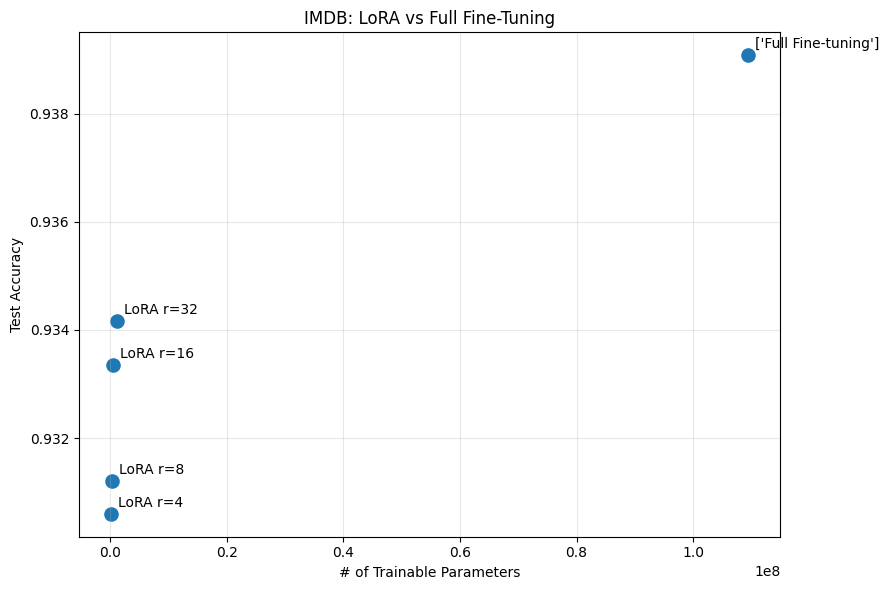

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    all_results["trainable_params"],
    all_results["test_accuracy"],
    s=90,
)

for _, row in all_results.iterrows():
    plt.annotate(
        row["model"],
        (row["trainable_params"], row["test_accuracy"]),
        xytext=(5, 5),
        textcoords="offset points",
    )

plt.xlabel("# of Trainable Parameters")
plt.ylabel("Test Accuracy")
plt.title("IMDB: LoRA vs Full Fine-Tuning")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Task 3

In [ ]:
rank = 32
set_seed(SEED)

base_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

# LoRA configuration
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=rank,
    lora_alpha=2 * rank,
    lora_dropout=LORA_DROPOUT,
    target_modules=["query", "value"],
    modules_to_save=["classifier"],
    bias="none",
)

model = get_peft_model(base_model, lora_config)

trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
total_params = sum(p.numel() for p in model.parameters())

print(f"Trainable parameters: {trainable_params:,}")
print(f"Total parameters: {total_params:,}")
print(f"Trainable percentage: {100 * trainable_params / total_params:.4f}%")

# Save checkpoints locally
output_dir = f"./checkpoints_rank_{rank}"
best_model_dir = f"./best_lora_rank_{rank}"

training_args = TrainingArguments(
    output_dir=output_dir,
    learning_rate=LORA_LR,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    num_train_epochs=EPOCHS,
    weight_decay=WEIGHT_DECAY,

    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,

    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,

    logging_strategy="steps",
    logging_steps=100,
    report_to="none",

    seed=SEED,
    data_seed=SEED,
    fp16=torch.cuda.is_available(),
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_data,
    eval_dataset=val_data,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

# Train and select the best checkpoint
trainer.train()

print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation accuracy:", trainer.state.best_metric)



# Evaluate on test set
test_metrics = trainer.evaluate(
    eval_dataset=test_data,
    metric_key_prefix="test"
)

accuracy = test_metrics["test_accuracy"]
print(f"Test accuracy for Rank 32: {accuracy:.4f}")


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 1,181,186
Total parameters: 110,664,964
Trainable percentage: 1.0674%


Epoch,Training Loss,Validation Loss,Accuracy
1,0.223053,0.202252,0.921200
2,0.185040,0.211041,0.921200
3,0.131265,0.226773,0.928400


Best checkpoint: ./checkpoints_rank_32/checkpoint-4221
Best validation accuracy: 0.9284


Training Loss,Validation Loss,Epoch,Accuracy
0.131265,0.200497,3,0.932960


Test accuracy for Rank 32: 0.9330


In [ ]:
# from peft import PeftModel
# from transformers import AutoModelForSequenceClassification, AutoTokenizer

# model_dir = "/content/drive/MyDrive/IMDB_LoRA_Models/best_lora_rank_32"

# base_model = AutoModelForSequenceClassification.from_pretrained(
#     MODEL_NAME,
#     num_labels=2
# )

# model = PeftModel.from_pretrained(base_model, model_dir)
# saved_tokenizer = AutoTokenizer.from_pretrained(model_dir)

# model.eval()

### training task 1 & 2 model to test and val dataset

In [ ]:
X_val = vectorizer.transform(val_data["text"])
X_test = vectorizer.transform(test_data["text"])


rf_val_probs = clf.predict_proba(X_val)
rf_test_probs = clf.predict_proba(X_test)

print("RF validation shape:", rf_val_probs.shape)
print("RF test shape:", rf_test_probs.shape)

RF validation shape: (2500, 2)
RF test shape: (25000, 2)


In [ ]:
inference_args = TrainingArguments(
    output_dir="./task3_inference",
    per_device_eval_batch_size=BATCH_SIZE,
    report_to="none",
    fp16=torch.cuda.is_available(),
)

inference_trainer = Trainer(
    model=model,
    args=inference_args,
    data_collator=data_collator,
)


val_output = inference_trainer.predict(val_data)


test_output = inference_trainer.predict(test_data)

lora_val_probs = softmax(val_output.predictions, axis=1)
lora_test_probs = softmax(test_output.predictions, axis=1)

print("LoRA validation shape:", lora_val_probs.shape)
print("LoRA test shape:", lora_test_probs.shape)

LoRA validation shape: (2500, 2)
LoRA test shape: (25000, 2)


### Train the meta-model

NOTE: The probability output from Task-1 and Task-2 model is used as feature to this meta model.


In [ ]:
X_meta_train = np.concatenate(
    [rf_val_probs, lora_val_probs],
    axis=1
)


X_meta_test = np.concatenate(
    [rf_test_probs, lora_test_probs],
    axis=1
)

y_meta_train = np.array(val_data["label"])
y_meta_test = np.array(test_data["label"])

print("Meta training shape:", X_meta_train.shape)
print("Meta testing shape:", X_meta_test.shape)

Meta training shape: (2500, 4)
Meta testing shape: (25000, 4)


In [ ]:
meta_model = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

meta_model.fit(X_meta_train, y_meta_train)

task3_preds = meta_model.predict(X_meta_test)

task3_accuracy = accuracy_score(
    y_meta_test,
    task3_preds
)

print(f"Task 3 Test Accuracy: {task3_accuracy:.4f}")

Task 3 Test Accuracy: 0.9298


In [ ]:

rf_test_preds = clf.predict(X_test)

rf_accuracy = accuracy_score(
    y_meta_test,
    rf_test_preds
)


lora_test_preds = np.argmax(
    lora_test_probs,
    axis=1
)

lora_accuracy = accuracy_score(
    y_meta_test,
    lora_test_preds
)

task3_accuracy = accuracy_score(
    y_meta_test,
    task3_preds
)

# Comparison
results = pd.DataFrame({
    "Model": [
        "Task 1 - Random Forest",
        "Task 2 - LoRA (r=32)",
        "Task 3 - RF + LoRA + Logistic Regression"
    ],
    "Test Accuracy": [
        rf_accuracy,
        lora_accuracy,
        task3_accuracy
    ]
})

results["Test Accuracy (%)"] = (
    results["Test Accuracy"] * 100
)

display(results)

,Model,Test Accuracy,Test Accuracy (%)
0,Task 1 - Random Forest,0.84712,84.712
1,Task 2 - LoRA (r=32),0.93296,93.296
2,Task 3 - RF + LoRA + Logistic Regression,0.92980,92.980


## [Task 3]Out-of-Fold (OOF) Approach

In [10]:
from sklearn.model_selection import StratifiedKFold

### Create the raw dataset and tokenized dataset

In [11]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [12]:
train = dataset["train"]
test = dataset["test"]


y = np.array(train["label"])
y_test = np.array(test["label"])

def tokenize_func(examples):
  return tokenizer(examples["text"], padding="max_length", truncation=True, max_length=MAX_LENGTH)

tokenized_train = train.map(tokenize_func, batched=True, remove_columns=["text"])
tokenized_test = test.map(tokenize_func, batched=True, remove_columns=["text"])

print("training samples:", len(train))
print("test samples:", len(test))

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

training samples: 25000
test samples: 25000


### Initialize the OOF arrays


In [13]:
N = len(train)

# two probabilities per model
rf_oof_probs = np.zeros((N, 2))
lora_oof_probs = np.zeros((N, 2))

# track which samples have received OOF predictions
oof_filled = np.zeros(N, dtype=bool)

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

print("OOF arrays initialized:", rf_oof_probs.shape)

OOF arrays initialized: (25000, 2)


### Initialize the OOF array

In [14]:
LORA_DROPOUT = 0.1
for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(N), y), start=1):
  print(f"Fold: {fold}/5")
  print("-" * 40)

  x_fold_train = [train[i]["text"] for i in train_idx]
  y_fold_train = y[train_idx]

  x_fold_val = [train[i]["text"] for i in val_idx]

  vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=20000)
  vectorizer.fit(x_fold_train)

  x_fold_train = vectorizer.transform(x_fold_train)
  x_fold_val = vectorizer.transform(x_fold_val)

  clf = RandomForestClassifier(
      n_estimators=300,
      max_depth=30,
      min_samples_leaf=5,
      random_state=42,
      n_jobs=-1
  )

  clf.fit(x_fold_train, y_fold_train)

  rf_probs = clf.predict_proba(x_fold_val)

  # ensure columns correspond to labels 0 and 1
  rf_probs = rf_probs[:, np.argsort(clf.classes_)]

  rf_oof_probs[val_idx] = rf_probs
  print("RF OOF predictions:", rf_probs.shape)

  del clf, vectorizer
  del x_fold_train, x_fold_val

  # LoRA
  fold_train_data = tokenized_train.select(train_idx.tolist())
  fold_val_data = tokenized_train.select(val_idx.tolist())

  set_seed(SEED)

  base_model = AutoModelForSequenceClassification.from_pretrained(
      MODEL_NAME,
      num_labels=2
  )

  lora_config = LoraConfig(
      task_type=TaskType.SEQ_CLS,
      r=32,
      lora_alpha=2 * 32,
      lora_dropout=LORA_DROPOUT,
      target_modules=["query", "value"],
      modules_to_save=["classifier"],
      bias="none"
  )
  lora_model = get_peft_model(base_model,lora_config)

  fold_output_dir = f"./oof_lora_fold_{fold}"

  fold_args = TrainingArguments(
      output_dir=fold_output_dir,
      learning_rate=LORA_LR,
      per_device_train_batch_size=BATCH_SIZE,
      per_device_eval_batch_size=BATCH_SIZE,
      num_train_epochs = EPOCHS,
      weight_decay=WEIGHT_DECAY,
      eval_strategy="no",
      save_strategy="no",

      logging_strategy = "steps",
      logging_steps = 100,
      report_to="none",
      seed = SEED,
      data_seed=SEED,
      fp16=torch.cuda.is_available()
  )

  fold_trainer = Trainer(
      model = lora_model,
      args = fold_args,
      train_dataset = fold_train_data,
      data_collator = data_collator,
      processing_class = tokenizer
  )

  fold_trainer.train()

  fold_output = fold_trainer.predict(fold_val_data)

  fold_probs = softmax(
      fold_output.predictions,
      axis=1
  )

  lora_oof_probs[val_idx] = fold_probs

  oof_filled[val_idx] = True
  print("LoRA OOF predictions: ", fold_probs.shape)
  print("Completed fold: ", fold)

  # Cleanup
  del fold_trainer, lora_model, base_model
  del fold_train_data, fold_val_data
  del fold_output

  gc.collect()

  if torch.cuda.is_available():
      torch.cuda.empty_cache()

print("All OOF predictions generated:", oof_filled.all())


Fold: 1/5
----------------------------------------
RF OOF predictions: (5000, 2)


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
100,0.512884
200,0.334608
300,0.279419
400,0.243923
500,0.276267
600,0.245252
700,0.243332
800,0.248976
900,0.227802
1000,0.252041


... (14 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
100,0.477943
200,0.326288
300,0.259268
400,0.266345
500,0.266992
600,0.218776
700,0.237005
800,0.253540
900,0.203213
1000,0.216647


LoRA OOF predictions:  (5000, 2)
Completed fold:  5
All OOF predictions generated: True


### verify OOF predictions

In [15]:
assert oof_filled.all(), "Some samples are missing OOF predictions!"

assert not np.isnan(rf_oof_probs).any()
assert not np.isnan(lora_oof_probs).any()

print("RF OOF:", rf_oof_probs.shape)
print("LoRA OOF:", lora_oof_probs.shape)

print("First RF prediction:", rf_oof_probs[0])
print("First LoRA prediction:", lora_oof_probs[0])

RF OOF: (25000, 2)
LoRA OOF: (25000, 2)
First RF prediction: [0.49595357 0.50404643]
First LoRA prediction: [0.81960475 0.18039528]


### Train final base models on the full training dataset

In [16]:
# Task 1: Final Random Forest

final_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=20000
)

X_full_train = final_vectorizer.fit_transform(
    train["text"]
)

X_full_test = final_vectorizer.transform(
    test["text"]
)

final_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=30,
    min_samples_leaf=5,
    random_state=SEED,
    n_jobs=-1
)

final_rf.fit(X_full_train, y)

rf_test_probs = final_rf.predict_proba(X_full_test)

rf_test_probs = rf_test_probs[:, np.argsort(final_rf.classes_)]

print("Final RF test predictions:", rf_test_probs.shape)

Final RF test predictions: (25000, 2)


In [21]:
set_seed(SEED)

base_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

final_lora = get_peft_model(
    base_model,
    LoraConfig(
        task_type=TaskType.SEQ_CLS,
        r=32,
        lora_alpha=64,
        lora_dropout=LORA_DROPOUT,
        target_modules=["query", "value"],
        modules_to_save=["classifier"],
        bias="none"
    )
)

final_args = TrainingArguments(
    output_dir="./final_lora_rank32",

    learning_rate=LORA_LR,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,

    num_train_epochs=EPOCHS,
    weight_decay=WEIGHT_DECAY,

    eval_strategy="no",
    save_strategy="no",

    logging_strategy="steps",
    logging_steps=100,

    report_to="none",

    seed=SEED,
    data_seed=SEED,

    fp16=torch.cuda.is_available()
)

final_trainer = Trainer(
    model=final_lora,
    args=final_args,
    train_dataset=tokenized_train,
    data_collator=data_collator,
    processing_class=tokenizer
)

final_trainer.train()

# # Save final LoRA model
# final_lora_dir = (
#     "/content/drive/MyDrive/IMDB_LoRA_Models/Task3/final_lora_rank32"
# )

# os.makedirs(final_lora_dir, exist_ok=True)

# final_trainer.save_model(final_lora_dir)
# tokenizer.save_pretrained(final_lora_dir)

# Test predictions
final_output = final_trainer.predict(tokenized_test)

lora_test_probs = softmax(
    final_output.predictions,
    axis=1
)

print("Final LoRA test predictions:", lora_test_probs.shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
100,0.520849
200,0.291799
300,0.297100
400,0.252013
500,0.262178
600,0.258745
700,0.259752
800,0.215944
900,0.243751
1000,0.248147


Final LoRA test predictions: (25000, 2)


### Train the Logistic Regression meta-model

In [22]:
# OOF meta-training features
X_meta_train = np.concatenate(
    [rf_oof_probs, lora_oof_probs],
    axis=1
)

# Test meta features
X_meta_test = np.concatenate(
    [rf_test_probs, lora_test_probs],
    axis=1
)

print("Meta training:", X_meta_train.shape)
print("Meta testing:", X_meta_test.shape)

# Train meta-model
meta_model = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

meta_model.fit(X_meta_train, y)

# Final ensemble predictions
task3_preds = meta_model.predict(X_meta_test)

print("Task 3 accuracy:",
      accuracy_score(y_test, task3_preds))

Meta training: (25000, 4)
Meta testing: (25000, 4)
Task 3 accuracy: 0.93708


### Compare Task 1, Task 2 and Task 3

In [23]:
# Individual model predictions
rf_test_preds = np.argmax(rf_test_probs, axis=1)
lora_test_preds = np.argmax(lora_test_probs, axis=1)

# Accuracies
rf_accuracy = accuracy_score(y_test, rf_test_preds)
lora_accuracy = accuracy_score(y_test, lora_test_preds)
task3_accuracy_oof = accuracy_score(y_test, task3_preds)

results_df = pd.DataFrame({
    "Model": [
        "Task 1 - Random Forest",
        "Task 2 - LoRA (r=32)",
        "Task 3 - RF + LoRA + Logistic Regression",
        "Task 3 - OOF Stacking"
    ],
    "Accuracy": [
        rf_accuracy,
        lora_accuracy,
        0.92980, #task3_accuracy,
        task3_accuracy_oof
    ]
})

results_df["Accuracy (%)"] = results_df["Accuracy"] * 100

display(results_df)

,Model,Accuracy,Accuracy (%)
0,Task 1 - Random Forest,0.84712,84.712
1,Task 2 - LoRA (r=32),0.93636,93.636
2,Task 3 - RF + LoRA + Logistic Regression,0.92980,92.980
3,Task 3 - OOF Stacking,0.93708,93.708


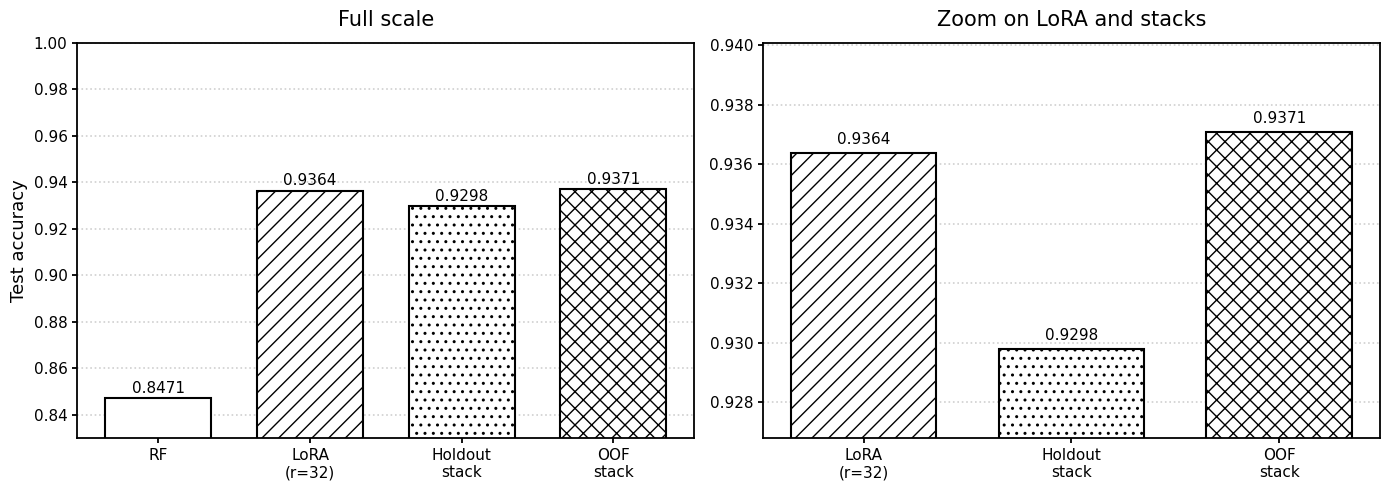

In [24]:
models = [
    "RF",
    "LoRA\n(r=32)",
    "Holdout\nstack",
    "OOF\nstack"
]

accuracies = results_df["Accuracy"].values

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    gridspec_kw={"width_ratios": [1, 1]}
)

x = np.arange(len(models))
hatches = ["", "//", "..", "xx"]

ax = axes[0]

bars = ax.bar(
    x,
    accuracies,
    width=0.7,
    color="white",
    edgecolor="black",
    linewidth=1.5
)

for bar, hatch in zip(bars, hatches):
    bar.set_hatch(hatch)

ax.set_title("Full scale", fontsize=15, pad=12)
ax.set_ylabel("Test accuracy", fontsize=13)
ax.set_xticks(x)
ax.set_xticklabels(models, fontsize=11)
ax.set_ylim(0.83, 1.00)

ax.set_yticks(np.arange(0.84, 1.001, 0.02))
ax.grid(axis="y", linestyle=":", alpha=0.6, linewidth=1.2)
ax.set_axisbelow(True)


for bar, value in zip(bars, accuracies):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.001,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=11
    )


ax = axes[1]

zoom_indices = [1, 2, 3]
zoom_models = [models[i] for i in zoom_indices]
zoom_accuracies = accuracies[zoom_indices]

bars = ax.bar(
    np.arange(len(zoom_indices)),
    zoom_accuracies,
    width=0.7,
    color="white",
    edgecolor="black",
    linewidth=1.5
)

for bar, i in zip(bars, zoom_indices):
    bar.set_hatch(hatches[i])

ax.set_title("Zoom on LoRA and stacks", fontsize=15, pad=12)
ax.set_xticks(np.arange(len(zoom_indices)))
ax.set_xticklabels(zoom_models, fontsize=11)


zoom_min = min(zoom_accuracies) - 0.003
zoom_max = max(zoom_accuracies) + 0.003

ax.set_ylim(zoom_min, zoom_max)
ax.grid(axis="y", linestyle=":", alpha=0.6, linewidth=1.2)
ax.set_axisbelow(True)


for bar, value in zip(bars, zoom_accuracies):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.0002,
        f"{value:.4f}",
        ha="center",
        va="bottom",
        fontsize=11
    )
for ax in axes:
    ax.tick_params(axis="both", labelsize=11, width=1.3)
    for spine in ax.spines.values():
        spine.set_linewidth(1.3)

plt.tight_layout()


plt.savefig(
    "model_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
